# Week 3 practical: Resampling and exploratory data analysis
**Data-driven AI | Lecturer solutions | 60-minute core session**

## Exercise-to-slide mapping

Numbers refer to the **1-based PowerPoint slide order** in `Week03_Lecture01_Resampling_EDA(1).pptx`, counting the title slide and both Vevox question/results slides. Each row lists the slides that directly support the activity. Optional exercises extend the listed concepts.

| Activity | Exact slides | Connection to the lecture | Core time |
|---|---|---|---:|
| Setup: packages and scenario | 12 | Python libraries and installation | 5 min |
| Exercise 1: audit the data and split it | 19, 20, 21, 23, 24, 25 | Reliable evaluation order, data-science workflow, variable types and EDA steps | 6 min |
| Exercise 2: univariate non-graphical EDA | 22, 26, 27, 28, 29 | Skewness, numerical summaries, categorical counts and percentages | 6 min |
| Exercise 3: univariate graphical EDA | 22, 33, 34, 35 | Histogram, boxplot and categorical frequency charts | 7 min |
| Exercise 4: multivariate non-graphical EDA | 30, 31, 32 | Cross-tabulation, within-group percentages and Pearson correlation | 6 min |
| Exercise 5: multivariate graphical EDA | 36, 37, 38, 39 | Scatter plots, side-by-side boxplots and a supplied pairplot example | 7 min |
| Exercise 6: class imbalance and classification metrics | 3, 4, 5, 6, 7, 8, 13, 14 | Class counts, majority-class prediction, confusion matrix, accuracy and recall | 8 min |
| Exercise 7: under-sampling, over-sampling and SMOTE | 9, 10, 15, 16, 17, 19, 20 | Three samplers, training-only preprocessing/resampling and model comparison | 12 min |
| Wrap-up: interpret the findings | 19, 20, 25 | Evaluation order and a short EDA report | 3 min |
| **Core total** | | **Setup + Exercises 1–7 + wrap-up** | **60 min** |
| Optional A: transform a skewed variable | 22, 34 | Extension of skewness and histogram interpretation | +8 min |
| Optional B: construct a synthetic minority point | 10, 11, 17 | SMOTE neighbours, interpolation and generated examples | +10 min |
| Optional C: compare feature pairs by class | 39, 40 | Pairwise plots, class overlap and feature informativeness | +8 min |
| Optional D: tune SMOTE inside cross-validation | 2, 19, 20 | Extension of pipelines and training-only operations; cross-validation is new material | +15 min |

**New scenario:** a parcel-delivery company wants to identify deliveries at risk of arriving late. The dataset is synthetic and generated inside this notebook. It contains no real customer data.


## How to use this notebook

Open [Google Colab](https://colab.research.google.com/), choose **File > Upload notebook**, and upload this `.ipynb`. A CPU runtime is sufficient. Run cells from top to bottom with **Shift+Enter**.

Complete the small `TODO` sections and the answer boxes in Exercises 1–7. Supplied preparation cells keep later exercises independent of earlier answers. Starter cells run without syntax errors. Empty results, blank axes or reminder messages indicate unfinished tasks. Optional A–D are outside the 60-minute core session.

**Working question:** which observed delivery conditions are associated with late arrivals, and how does resampling change a model's ability to detect them?

All five numerical predictors describe conditions available when a delivery is dispatched. Categorical variables support EDA. To keep ordinary SMOTE appropriate and the practical short, the classifier uses only the five continuous numerical predictors.

| Column | Meaning / unit | Role |
|---|---|---|
| `delivery_id` | Unique record number | Identifier, excluded from EDA statistics and models |
| `distance_km` | Planned route distance in km | Numerical predictor |
| `parcel_weight_kg` | Parcel weight in kg | Numerical predictor |
| `traffic_index` | Expected traffic, 0 (low) to 10 (high) | Numerical predictor |
| `depot_load_pct` | Dispatch workload, 0–100% | Numerical predictor |
| `rain_mm` | Forecast rainfall in mm | Numerical predictor |
| `route_zone` | Urban, Suburban or Rural | Categorical predictor for EDA |
| `service_type` | Standard or Express | Categorical predictor for EDA |
| `late` | 0 = on time, 1 = late | Binary categorical target |

The generated export deliberately includes missing numerical entries and three exact duplicate rows. A fixed seed reproduces the dataset. Relationships are designed for teaching and do not establish how a real delivery company operates.


## Lecturer delivery guide

Students should reach Exercise 4 by minute 24, Exercise 6 by minute 37, and Exercise 7 by minute 45. Keep discussion answers to one or two sentences. The pairplot in Exercise 5 and model-fitting loop in Exercise 7 are supplied demonstrations.

This version includes completed code, worked interpretations and outputs for every core and optional exercise. Share the student workbook first and release this version after the session. If time is tight, discuss Exercise 5's supplied pairplot as a group and preserve time for resampling.

The core model comparison is a fixed teaching experiment on one hold-out set. It supports discussion, not model selection claims. Optional D uses training-fold validation to choose settings without reusing the test set.


## Setup (5 minutes)

Run the installation cell **before importing packages**. The distribution to install is `imbalanced-learn`, and the Python module to import is `imblearn`. The scikit-learn/imbalanced-learn pair is pinned for reproducible teaching. The other packages are normally available in Colab; this cell also covers a fresh Jupyter environment.

If you already imported different package versions in this runtime, restart the session after installation, then rerun from the import cell. No GPU, Drive mount or external dataset file is required.


In [ ]:
%pip install -q "scikit-learn==1.7.2" "imbalanced-learn==0.14.0" "numpy>=1.25.2,<3" "pandas>=2.0,<3" "matplotlib>=3.7,<4" "seaborn>=0.12,<1"


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
BLUE = '#2563a6'
ORANGE = '#d97706'
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 12)
print('scikit-learn:', sklearn.__version__, '| imbalanced-learn:', imblearn.__version__)


scikit-learn: 1.7.2 | imbalanced-learn: 0.14.0


### Generate the delivery data (supplied)

Run this cell unchanged. In the simulation, distance, traffic, workload and weather contribute to a noisy delay score. The highest 10% become late deliveries. The label records an outcome after delivery; it must never become a model input.


In [2]:
def make_delivery_data(seed=SEED, n=1000):
    rng = np.random.default_rng(seed)
    distance = np.clip(rng.lognormal(3.5, 0.5, n), 5, 180).round(1)
    weight = np.clip(rng.gamma(2, 2, n), 0.2, 25).round(1)
    traffic = np.clip(10 * rng.beta(2, 2, n), 0, 10).round(1)
    load = np.clip(45 + 4.5 * traffic + rng.normal(0, 10, n), 20, 100).round(1)
    rain = np.where(rng.random(n) < 0.4, 0, rng.gamma(1.2, 3, n)).round(1)
    service = rng.choice(['Standard', 'Express'], n, p=[0.75, 0.25])
    zone = np.where(distance < 25, 'Urban', np.where(distance < 50, 'Suburban', 'Rural'))

    def zscore(values):
        return (values - values.mean()) / values.std()

    risk = (
        0.7 * zscore(np.log1p(distance))
        + 0.9 * zscore(traffic)
        + 0.6 * zscore(load)
        + 0.45 * zscore(np.log1p(rain))
        - 0.5 * (service == 'Express')
        + rng.normal(0, 1.4, n)
    )
    late = np.zeros(n, dtype=int)
    late[np.argsort(risk)[-int(0.1 * n):]] = 1
    data = pd.DataFrame({
        'delivery_id': np.arange(1, n + 1),
        'distance_km': distance,
        'parcel_weight_kg': weight,
        'traffic_index': traffic,
        'depot_load_pct': load,
        'rain_mm': rain,
        'route_zone': zone,
        'service_type': service,
        'late': late,
    })
    duplicate_positions = [3, 41, 88]
    available = np.setdiff1d(np.arange(n), duplicate_positions)
    missing_positions = rng.choice(available, 20, replace=False)
    data.loc[missing_positions[:12], 'traffic_index'] = np.nan
    data.loc[missing_positions[12:], 'parcel_weight_kg'] = np.nan
    return pd.concat([data, data.iloc[duplicate_positions]], ignore_index=True)

raw = make_delivery_data()
numeric_features = ['distance_km', 'parcel_weight_kg', 'traffic_index', 'depot_load_pct', 'rain_mm']
categorical_features = ['route_zone', 'service_type']
display(raw.head())


,delivery_id,distance_km,parcel_weight_kg,traffic_index,depot_load_pct,rain_mm,route_zone,service_type,late
0,1,38.6,3.2,5.4,57.2,0.0,Suburban,Standard,0
1,2,19.7,2.4,6.1,78.0,3.2,Urban,Standard,0
2,3,48.2,3.3,5.1,59.7,4.0,Suburban,Standard,1
3,4,53.0,5.4,4.7,77.1,0.6,Rural,Standard,1
4,5,12.5,5.7,3.6,48.3,0.0,Urban,Standard,0


## Exercise 1: Data audit and a reliable split (6 minutes)
**Slides 19–21 and 23–25**

1. Display the dataset's shape, column types, missing values per column and exact duplicate count.
2. Run the supplied cleaning/split cell. Explain why duplicate export rows need attention before the split, and why `delivery_id` is excluded from the model.

**Hints:** `.shape`, `.dtypes`, `.isna().sum()` and `.duplicated().sum()`.


In [3]:
shape = raw.shape
column_types = raw.dtypes
missing_counts = raw.isna().sum()
duplicate_count = raw.duplicated().sum()

print('Shape:', shape)
print('Exact duplicate rows:', duplicate_count)
display(column_types.rename('dtype').to_frame())
display(missing_counts.rename('missing').to_frame())


Shape: (1003, 9)
Exact duplicate rows: 3


,dtype
delivery_id,int64
distance_km,float64
parcel_weight_kg,float64
traffic_index,float64
depot_load_pct,float64
rain_mm,float64
route_zone,object
service_type,object
late,int64


,missing
delivery_id,0
distance_km,0
parcel_weight_kg,8
traffic_index,12
depot_load_pct,0
rain_mm,0
route_zone,0
service_type,0
late,0


In [4]:
# Supplied: remove known duplicate export rows, then split before EDA or fitting.
data = raw.drop_duplicates().reset_index(drop=True)
train_df, test_df = train_test_split(
    data, test_size=0.20, stratify=data['late'], random_state=SEED
)
train_df = train_df.copy()
test_df = test_df.copy()
eda = train_df.copy()  # Use only this training frame for all EDA exercises.
X_train, y_train = train_df[numeric_features], train_df['late']
X_test, y_test = test_df[numeric_features], test_df['late']
test_X_snapshot, test_y_snapshot = X_test.copy(deep=True), y_test.copy(deep=True)

print(f'Unique deliveries: {len(data)} | Training: {len(train_df)} | Test: {len(test_df)}')
print('EDA uses training deliveries. Numerical gaps remain for training-only imputation later.')


Unique deliveries: 1000 | Training: 800 | Test: 200
EDA uses training deliveries. Numerical gaps remain for training-only imputation later.


**Your answer:** Why can duplicates across training and test sets distort evaluation? Why is an arbitrary ID a poor predictor?

_Write one or two sentences here._


**Lecturer solution and teaching notes**

The raw export has **1,003 rows and 9 columns**, **3 duplicates**, **12 missing traffic values** and **8 missing weight values**. Removing the export duplicates leaves 1,000 deliveries: 800 for training and 200 for testing.

A duplicated delivery appearing in both partitions can make evaluation optimistic because the model has effectively seen that case. Here the repeats are known export duplicates; identical feature values alone would not justify deletion in a real dataset. `delivery_id` identifies a record and has no justified predictive meaning. Leave numerical gaps in place until a training-only imputer is fitted.


## Exercise 2: Univariate non-graphical EDA (6 minutes)
**Slides 22 and 26–29**

For `parcel_weight_kg`, calculate the mean, median, all modes, sample standard deviation, minimum, maximum, quartiles, IQR and skewness. Complete the categorical frequency table for `service_type`, including percentages.

**Hints:** `.agg(['mean', 'median', 'std', 'min', 'max', 'skew'])`, `.mode()`, `.quantile([0.25, 0.75])`, `.value_counts()` and `100 * counts / counts.sum()`. Pandas summaries skip missing numerical entries. A rounded continuous variable can have several modes.


In [5]:
weights = eda['parcel_weight_kg']
summary = weights.agg(['mean', 'median', 'std', 'min', 'max', 'skew'])
modes = weights.mode()
quartiles = weights.quantile([0.25, 0.75])
service_counts = eda['service_type'].value_counts()

display(summary.round(3).to_frame('value'))
print('Mode(s), kg:', modes.tolist())
display(quartiles.to_frame('kg'))
print('IQR, kg:', round(quartiles.loc[0.75] - quartiles.loc[0.25], 3))
display(pd.DataFrame({'count': service_counts,
                      'percentage': 100 * service_counts / service_counts.sum()}).round(1))
print('Most frequent service type(s):', eda['service_type'].mode().tolist())


Mode(s), kg: [2.1]
IQR, kg: 3.45
Most frequent service type(s): ['Standard']


,value
mean,4.060
median,3.400
std,2.922
min,0.200
max,19.100
skew,1.463


,kg
0.25,1.95
0.75,5.40


,count,percentage
service_type,,
Standard,609,76.1
Express,191,23.9


**Your answer:** Is parcel weight approximately symmetric or skewed? Which measure of central tendency would you report for a typical parcel, and why?

_Write your answer here._


**Lecturer solution and teaching notes**

Weight has a positive skew (**1.463**) and a longer right tail. Its mean is **4.06 kg**, median **3.40 kg**, mode **2.10 kg**, sample standard deviation **2.92 kg** and IQR **3.45 kg**. The median is a useful description of a typical parcel because a few heavy parcels pull the mean upward. A mode for weight depends on the rounding resolution; it is less stable as a summary of a continuous quantity. Standard is the modal service category (**609 of 800**, or **76.1%**). The percentages use 800 training deliveries as their denominator.


## Exercise 3: Univariate graphical EDA (7 minutes)
**Slides 22 and 33–35**

Add a weight histogram and weight boxplot to the first figure. Add a service-type count plot and a pie chart to the second figure. Use the supplied axes so all charts remain readable.

**Hints:** `sns.histplot(data=eda, x='parcel_weight_kg', bins=20, ax=axes[0])`, `sns.boxplot(...)`, `sns.countplot(...)` and `axes[1].pie(...)`. Pass `data=`, `x=` and `y=` explicitly in Seaborn.


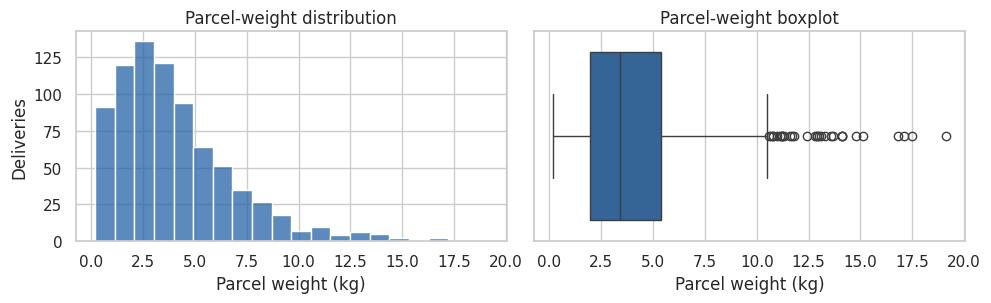

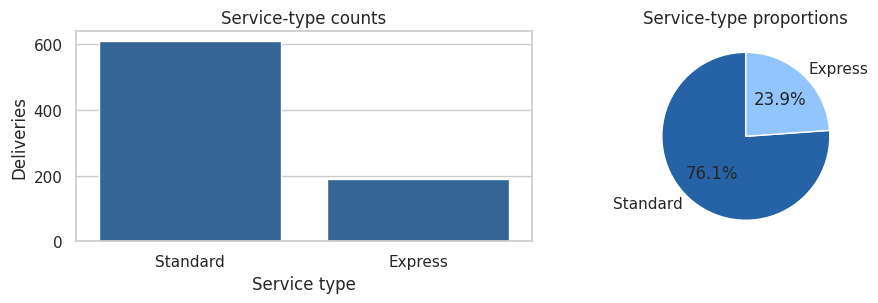

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.histplot(data=eda, x='parcel_weight_kg', bins=20, color=BLUE, ax=axes[0])
sns.boxplot(data=eda, x='parcel_weight_kg', color=BLUE, ax=axes[1])
axes[0].set(title='Parcel-weight distribution', xlabel='Parcel weight (kg)', ylabel='Deliveries')
axes[1].set(title='Parcel-weight boxplot', xlabel='Parcel weight (kg)')
plt.tight_layout()
plt.show()

counts_for_plot = eda['service_type'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.countplot(data=eda, x='service_type', order=counts_for_plot.index, color=BLUE, ax=axes[0])
axes[1].pie(counts_for_plot, labels=counts_for_plot.index,
            autopct='%1.1f%%', startangle=90, colors=[BLUE, '#93c5fd'])
axes[0].set(title='Service-type counts', xlabel='Service type', ylabel='Deliveries')
axes[1].set_title('Service-type proportions')
plt.tight_layout()
plt.show()


**Your answer:** What does each numerical plot reveal? Are points outside the boxplot whiskers necessarily errors? Which categorical chart makes counts easier to compare?

_Write your answer here._


**Lecturer solution and teaching notes**

The histogram reveals distribution shape and the right tail. The boxplot summarises the median, quartiles and observations beyond the usual 1.5×IQR fences. These observations can be valid heavy parcels, so investigate them before deciding on removal. A count/bar chart makes category sizes easier to compare on a common scale; a pie chart emphasises their shares of the whole.


## Exercise 4: Multivariate non-graphical EDA (6 minutes)
**Slides 30–32**

Cross-tabulate `service_type` against `late`. Then calculate percentages **within each service type**. Finally, calculate a Pearson correlation matrix across the five numerical predictors.

**Hints:** `pd.crosstab(eda['service_type'], eda['late'])`, `normalize='index'`, and `eda[numeric_features].corr()`. Use counts and percentages together because the groups have different sizes. Correlation uses pairs of non-missing observations.


late,On time,Late
service_type,,
Express,183,8
Standard,537,72


late,On time (%),Late (%)
service_type,,
Express,95.8,4.2
Standard,88.2,11.8


,distance_km,parcel_weight_kg,traffic_index,depot_load_pct,rain_mm
distance_km,1.00,-0.01,0.01,0.07,0.00
parcel_weight_kg,-0.01,1.00,-0.01,-0.01,-0.07
traffic_index,0.01,-0.01,1.00,0.69,-0.02
depot_load_pct,0.07,-0.01,0.69,1.00,-0.05
rain_mm,0.00,-0.07,-0.02,-0.05,1.00


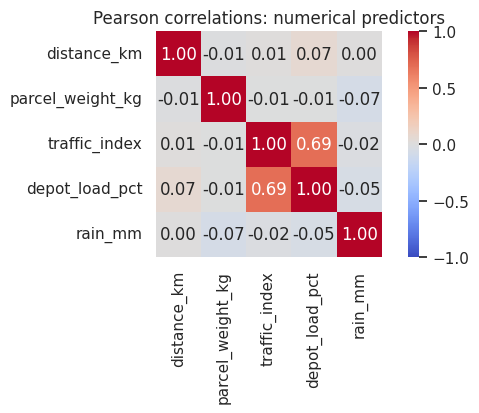

In [7]:
cross_counts = pd.crosstab(eda['service_type'], eda['late'])
cross_percent = 100 * pd.crosstab(eda['service_type'], eda['late'], normalize='index')
correlations = eda[numeric_features].corr()

display(cross_counts.rename(columns={0: 'On time', 1: 'Late'}))
display(cross_percent.rename(columns={0: 'On time (%)', 1: 'Late (%)'}).round(1))
display(correlations.round(2))
plt.figure(figsize=(6.4, 4.3))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True)
plt.title('Pearson correlations: numerical predictors')
plt.tight_layout()
plt.show()


**Your answer:** Compare late-delivery rates for Standard and Express. Which two numerical predictors have the strongest positive correlation? Does an association prove causation?

_Write your answer here._


**Lecturer solution and teaching notes**

Standard has a higher observed late-delivery percentage: **72/609 = 11.8%**, compared with **8/191 = 4.2%** for Express. Use these within-service rates rather than comparing late counts alone. Traffic and depot workload have the strongest positive numerical correlation (**r ≈ 0.69**). Their relationship is built into the simulation. These descriptive associations cannot establish a causal effect in real operations. A small Pearson coefficient can also hide a nonlinear relationship.


## Exercise 5: Multivariate graphical EDA (7 minutes)
**Slides 36–39**

Add a scatter plot of traffic versus depot load, and side-by-side boxplots of traffic for on-time versus late deliveries. Then run the supplied pairplot example.

**Hints:** `sns.scatterplot(data=eda, x=..., y=..., ax=axes[0])` and `sns.boxplot(data=eda, x='late', y=..., order=[0, 1], ax=axes[1])`.


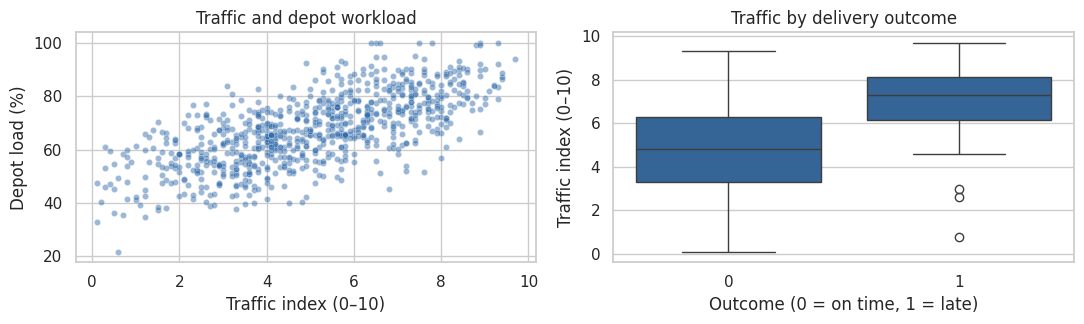

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.scatterplot(data=eda, x='traffic_index', y='depot_load_pct',
                color=BLUE, alpha=0.45, s=20, ax=axes[0])
sns.boxplot(data=eda, x='late', y='traffic_index', order=[0, 1], color=BLUE, ax=axes[1])
axes[0].set(title='Traffic and depot workload', xlabel='Traffic index (0–10)', ylabel='Depot load (%)')
axes[1].set(title='Traffic by delivery outcome', xlabel='Outcome (0 = on time, 1 = late)',
            ylabel='Traffic index (0–10)')
plt.tight_layout()
plt.show()


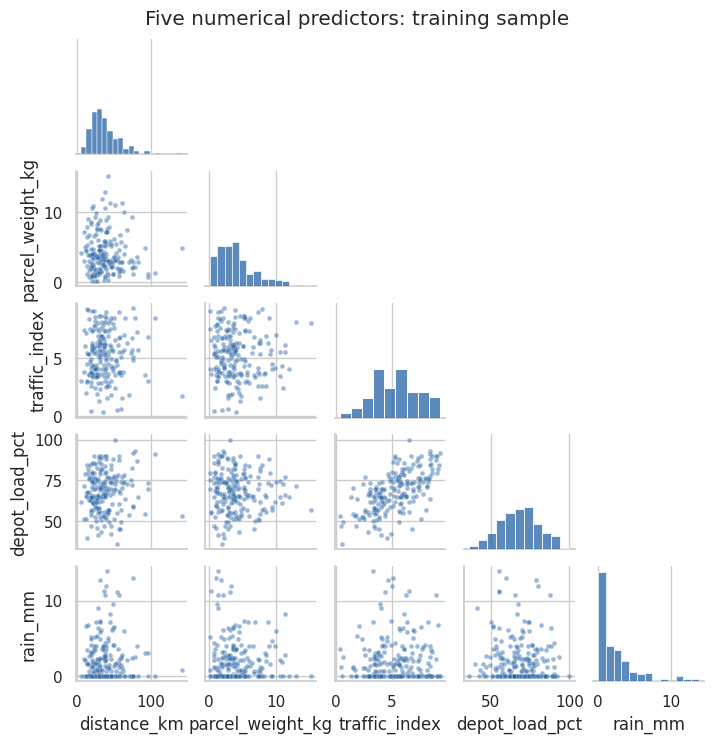

In [9]:
# Supplied worked example: sample only the training frame for a compact pairplot.
pair_data = eda[numeric_features].dropna().sample(n=200, random_state=SEED)
grid = sns.pairplot(pair_data, diag_kind='hist', corner=True, height=1.45,
                    plot_kws={'s': 12, 'alpha': 0.45, 'color': BLUE},
                    diag_kws={'color': BLUE})
grid.fig.suptitle('Five numerical predictors: training sample', y=1.02)
plt.show()


**Your answer:** Describe the scatter-plot trend and the overlap in the grouped boxplots. What do the diagonal panels of the pairplot show?

_Write your answer here._


**Lecturer solution and teaching notes**

Depot workload generally increases with traffic. Late deliveries tend to have higher traffic, but the group distributions overlap, so traffic alone will not perfectly identify late cases. Pairplot diagonals show individual-variable histograms. Off-diagonal panels show relationships between pairs. Missing values are omitted only for plotting; the modelling section handles them with a training-only imputer.


## Exercise 6: Why accuracy can mislead (8 minutes)
**Slides 3–8 and 13–14**

Calculate training class counts and percentages. Run the supplied majority-class classifier and confusion matrix. It always predicts **on time**. Complete the accuracy and late-class recall formulas from its counts.

**Positive class = late (1).** A false positive triggers an unnecessary delay alert. A false negative misses a delivery that arrives late.

$$\mathrm{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN},\qquad
\mathrm{Recall} = \frac{TP}{TP+FN}$$

The confusion matrix has actual classes on rows and predicted classes on columns, both ordered `[0, 1]`. Precision is undefined if no positive predictions exist. Our reporting helper uses `zero_division=0` to display 0 in that case.


,count,percentage
late,,
0,720,90.0
1,80,10.0


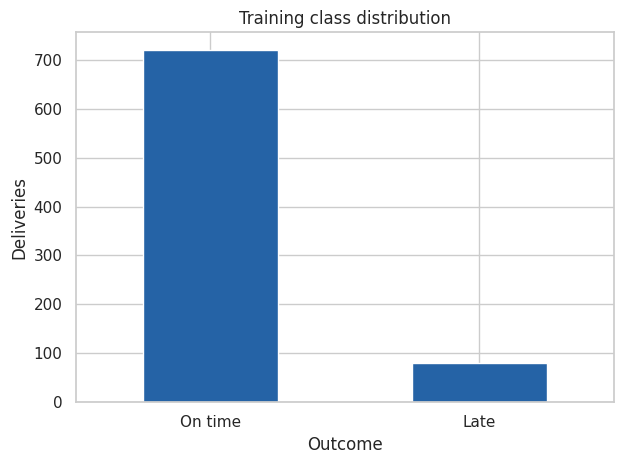

In [10]:
class_counts = y_train.value_counts().sort_index()
display(pd.DataFrame({'count': class_counts,
                      'percentage': 100 * class_counts / class_counts.sum()}).round(1))
ax = class_counts.rename(index={0: 'On time', 1: 'Late'}).plot.bar(color=BLUE, rot=0)
ax.set(title='Training class distribution', xlabel='Outcome', ylabel='Deliveries')
plt.tight_layout()
plt.show()


TN=180, FP=0, FN=20, TP=0


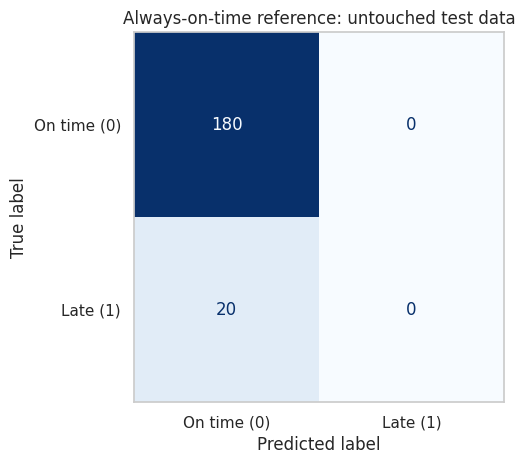

In [11]:
# Supplied: a deliberately simple reference model.
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
cm = confusion_matrix(y_test, dummy_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
display_cm = ConfusionMatrixDisplay(cm, display_labels=['On time (0)', 'Late (1)']).plot(cmap='Blues', colorbar=False)
display_cm.ax_.grid(False)
plt.title('Always-on-time reference: untouched test data')
plt.tight_layout()
plt.show()


In [12]:
accuracy_manual = (tp + tn) / (tp + tn + fp + fn)
recall_manual = tp / (tp + fn)
print('Accuracy:', accuracy_manual)
print('Late-class recall:', recall_manual)


Accuracy: 0.9
Late-class recall: 0.0


**Your answer:** Would the always-on-time classifier help a team trying to detect late deliveries? If delay alerts trigger a free courtesy message, which error might matter more? If alerts trigger expensive emergency transport, how might the priority change?

_Write your answer here._


**Lecturer solution and teaching notes**

Training contains **720 on-time and 80 late deliveries**. Testing contains **180 on-time and 20 late deliveries**. The reference confusion matrix is `[[180, 0], [20, 0]]`: **90% accuracy and 0% late-class recall**. It detects none of the late cases. Its balanced accuracy is 0.5.

When an alert only sends a courtesy message, missing a delay may matter more and higher recall may be useful. Expensive emergency transport makes unnecessary alerts costly, increasing the importance of precision. The decision depends on actual costs and available interventions. F1 balances precision and recall equally and does not encode those costs.


### Supplied modelling preparation and baseline

Fit the median imputer and scaler using `X_train`, then use those same fitted objects to transform `X_test`. Scaling gives the numerical features comparable units for SMOTE's distance calculations. Fit a fixed logistic-regression baseline before resampling.

This preparation cell is supplied so Exercise 7 focuses on the sampling methods. EDA used the original, imbalanced training data; we do not infer population proportions from a balanced resampled dataset.


In [13]:
preprocessor = SklearnPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

def metric_row(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (late)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (late)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1 (late)': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
    }

baseline = LogisticRegression(max_iter=1000, random_state=SEED)
baseline.fit(X_train_prepared, y_train)
baseline_pred = baseline.predict(X_test_prepared)
display(pd.DataFrame([metric_row(y_test, baseline_pred)], index=['No resampling']).round(3))


,Accuracy,Precision (late),Recall (late),F1 (late),Balanced accuracy
No resampling,0.915,0.615,0.4,0.485,0.686


## Exercise 7: Resample training data and compare (12 minutes)
**Slides 9–10, 15–17 and 19–20**

Before running, predict the new training counts for each method. Replace the three `None` entries with `RandomUnderSampler`, `RandomOverSampler` and `SMOTE` objects. Give each `random_state=SEED`; set SMOTE's `k_neighbors=3` to match slide 10.

Run the supplied loop. Every method starts from the **same original prepared training data**, and the same classifier settings. All predictions use the **same untouched 200-delivery test set**, preserving its class imbalance.

**Hints:** `RandomUnderSampler(random_state=SEED)`, `RandomOverSampler(random_state=SEED)` and `SMOTE(random_state=SEED, k_neighbors=3)`. Default sampling balances the two classes. Ordinary SMOTE interpolates continuous numerical features; do not apply it directly to arbitrary category codes or identifiers.


In [14]:
samplers = {
    'Under-sampling': RandomUnderSampler(random_state=SEED),
    'Over-sampling': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED, k_neighbors=3),
}


Every method was evaluated on the same 200 original test deliveries.


,On time,Late
Method,,
Original training,720,80
Under-sampling,80,80
Over-sampling,720,720
SMOTE,720,720


,Accuracy,Precision (late),Recall (late),F1 (late),Balanced accuracy
Method,,,,,
Always on time,0.900,0.000,0.0,0.000,0.500
No resampling,0.915,0.615,0.4,0.485,0.686
Under-sampling,0.855,0.390,0.8,0.525,0.831
Over-sampling,0.855,0.400,0.9,0.554,0.875
SMOTE,0.855,0.400,0.9,0.554,0.875


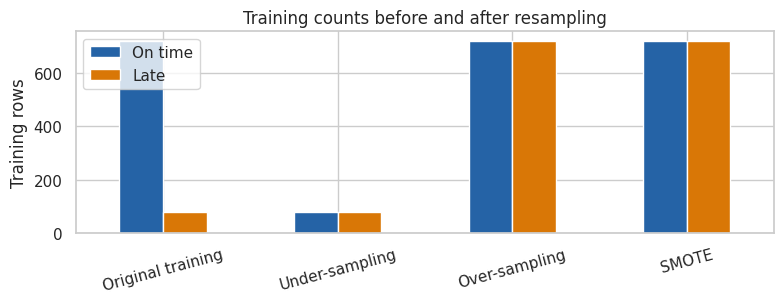

In [15]:
# Supplied comparison loop. Each sampler sees training data only.
rows = [
    {'Method': 'Always on time', **metric_row(y_test, dummy_pred)},
    {'Method': 'No resampling', **metric_row(y_test, baseline_pred)},
]
count_rows = [{'Method': 'Original training',
               'On time': int((y_train == 0).sum()), 'Late': int((y_train == 1).sum())}]
fitted_models = {'No resampling': baseline}
for name, sampler in samplers.items():
    if sampler is None:
        print(f'{name}: complete the sampler constructor above, then rerun this cell.')
        continue
    X_resampled, y_resampled = sampler.fit_resample(X_train_prepared, y_train)
    count_rows.append({'Method': name,
                       'On time': int((y_resampled == 0).sum()),
                       'Late': int((y_resampled == 1).sum())})
    model = LogisticRegression(max_iter=1000, random_state=SEED)
    model.fit(X_resampled, y_resampled)
    fitted_models[name] = model
    rows.append({'Method': name, **metric_row(y_test, model.predict(X_test_prepared))})

resampling_counts = pd.DataFrame(count_rows).set_index('Method')
comparison = pd.DataFrame(rows).set_index('Method')
display(resampling_counts)
display(comparison.round(3))
ax = resampling_counts.plot.bar(figsize=(8, 3.2), color=[BLUE, ORANGE], rot=15)
ax.set(title='Training counts before and after resampling', xlabel='', ylabel='Training rows')
plt.tight_layout()
plt.show()

# The test features and labels must remain exactly as split in Exercise 1.
assert X_test.equals(test_X_snapshot) and y_test.equals(test_y_snapshot)
print(f'Every method was evaluated on the same {len(y_test)} original test deliveries.')


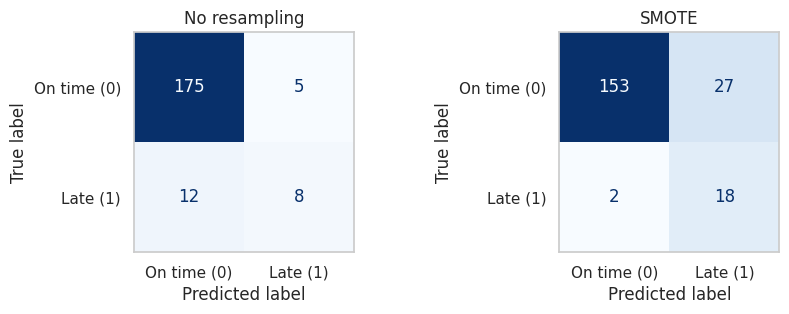

In [16]:
# Supplied: compare a real baseline with SMOTE's model using both FP and FN.
if 'SMOTE' in fitted_models:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
    for ax, name in zip(axes, ['No resampling', 'SMOTE']):
        predictions = fitted_models[name].predict(X_test_prepared)
        ConfusionMatrixDisplay.from_predictions(
            y_test, predictions, labels=[0, 1],
            display_labels=['On time (0)', 'Late (1)'],
            ax=ax, cmap='Blues', colorbar=False,
        )
        ax.set_title(name)
        ax.grid(False)
    plt.tight_layout()
    plt.show()
else:
    print('Complete the SMOTE constructor and rerun the comparison loop to see this figure.')


**Your answers:**

- Which method discards observations? Which repeats existing observations? Which creates synthetic observations?
- Compare baseline and SMOTE recall, precision, false positives and false negatives. What trade-off do you observe?
- Why would balancing the test set or creating SMOTE points before splitting distort evaluation?

_Write your answers here. A balanced training set does not guarantee a better classifier._


**Lecturer solution and teaching notes**

| Training set | On time | Late | Total |
|---|---:|---:|---:|
| Original | 720 | 80 | 800 |
| Random under-sampling | 80 | 80 | 160 |
| Random over-sampling | 720 | 720 | 1,440 |
| SMOTE | 720 | 720 | 1,440 |

Under-sampling removes majority observations and loses information. Over-sampling repeats minority observations, which can increase overfitting. SMOTE adds 640 interpolated minority points in feature space; these are synthetic teaching examples, not additional observed deliveries.

With the fixed data and package pair, the unsampled baseline has **91.5% accuracy, 61.5% precision and 40% recall**. Its confusion matrix is `[[175, 5], [12, 8]]`, so it misses 12 late deliveries and creates 5 false alerts. SMOTE has **85.5% accuracy, 40% precision and 90% recall**, with matrix `[[153, 27], [2, 18]]`. It misses only 2 late deliveries but creates 27 false alerts. F1 increases from **0.485 to 0.554** in this run. Random over-sampling happens to give the same rounded scores as SMOTE here.

This example illustrates a recall/precision trade-off. A resampled model can also have better recall but worse F1 on another dataset. No method is guaranteed to improve all metrics or to outperform the others. The class-count results are exact; small numerical changes across other package versions may affect fitted-model scores.

Resampling before splitting can use future test observations to create training points and can spread duplicate over-sampled points across partitions. Resampling the test data changes the evaluation population's prevalence. Imputation and scaling also learn from the training partition only. In cross-validation, repeat all fitting/resampling within each training fold, as in Optional D.


## Wrap-up (3 minutes)
**Slides 19–20 and 25**

Write three brief statements for the operations team:

1. One data-quality issue and how you handled it.
2. One EDA finding supported by a table or plot.
3. One resampling trade-off, using recall and precision or the confusion matrix.

_Write your mini-report here._

Save your completed notebook. You have finished the 60-minute core practical. If time remains, choose an optional exercise below.


**Lecturer solution and teaching notes**

Example: “We removed three duplicate export rows and filled numerical gaps using training medians for modelling. In the training data, late deliveries tended to experience higher traffic, although the distributions overlapped. SMOTE detected more late cases than the unsampled model but generated more unnecessary alerts. The intervention cost should guide the next modelling step.”

Accept other interpretations when they accurately describe the displayed results. Students should avoid claiming causation or assuming the balanced method with the highest accuracy is automatically preferable.


# Optional exercises

These tasks extend the lecture and are **outside the one-hour core plan**. Each uses the supplied training data/preparation and can be attempted independently after Exercise 6. Optional B uses only continuous numerical features. Optional D uses fresh pipelines fitted on the original training frame, so its validation folds remain isolated.

## Optional A: A skewness transformation (about 8 minutes)
**Slides 22 and 34**

Apply `np.log1p` to observed parcel weights. Compare skewness before and after, then plot both histograms. Why does `log1p(x)` also work when `x=0`? Is zero skewness required before fitting every model?

**Hint:** Work on `eda['parcel_weight_kg'].dropna()`. A transformation for a future model must be chosen from training evidence and applied consistently to new inputs.


,value
Original skewness,1.463
Log1p skewness,-0.067


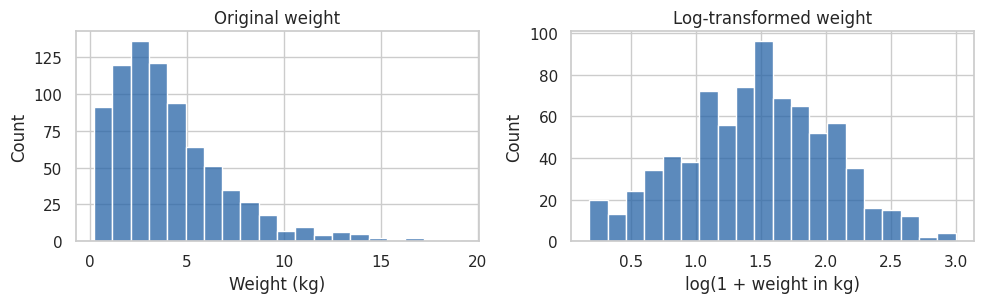

In [17]:
observed_weights = eda['parcel_weight_kg'].dropna()
log_weights = np.log1p(observed_weights)
display(pd.Series({'Original skewness': observed_weights.skew(),
                   'Log1p skewness': log_weights.skew()}).round(3).to_frame('value'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.histplot(observed_weights, bins=20, color=BLUE, ax=axes[0])
sns.histplot(log_weights, bins=20, color=BLUE, ax=axes[1])
axes[0].set(title='Original weight', xlabel='Weight (kg)')
axes[1].set(title='Log-transformed weight', xlabel='log(1 + weight in kg)')
plt.tight_layout()
plt.show()


**Your answer:** _Write your interpretation here._


**Lecturer solution and teaching notes**

`log1p(0)=log(1)=0`, so it handles zero values. It compresses the high-weight tail and changes skewness from **1.463 to −0.067** in this example. It also changes the scale and interpretation of the variable. Predictors do not universally need symmetric distributions or zero skewness. Whether the transformation helps a particular model requires validation using training data.


## Optional B: Make one SMOTE point by hand (about 10 minutes)
**Slides 10–11 and 17**

The supplied preparation selects a late-delivery point and its three nearest **minority-class** neighbours using the same five scaled predictors as the main SMOTE example. Complete the interpolation with $lambda=0.35$:

$$x_{mathrm{new}}=x_i+lambda(x_j-x_i).$$

Use the **same** lambda for every feature. The supplied plot projects the five-dimensional interpolation onto traffic/load axes. Try changing lambda to 0 and 1. Why must a nearest neighbour come from the same class? Why is a two-feature projection unable to show all five-dimensional distances?


In [18]:
# Supplied: find three neighbours of one minority point (excluding itself).
minority = X_train_prepared[y_train.to_numpy() == 1]
neighbour_model = NearestNeighbors(n_neighbors=4).fit(minority)
neighbour_distances, neighbour_indices = neighbour_model.kneighbors(minority[[0]])
nearest_three = neighbour_indices[0, 1:]
x_i = minority[0]
x_j = minority[nearest_three[0]]  # Fixed neighbour makes the example reproducible.
lam = 0.35
print('Three nearest minority-neighbour indices:', nearest_three)
print('Three distances in scaled five-feature space:', neighbour_distances[0, 1:].round(3))


Three nearest minority-neighbour indices: [32 73 64]
Three distances in scaled five-feature space: [1.133 1.173 1.176]


,distance_km,parcel_weight_kg,traffic_index,depot_load_pct,rain_mm
Start,1.161,-0.672,1.409,0.365,0.059
Neighbour,0.612,-0.809,0.695,0.750,-0.495
Synthetic,0.969,-0.720,1.159,0.500,-0.135


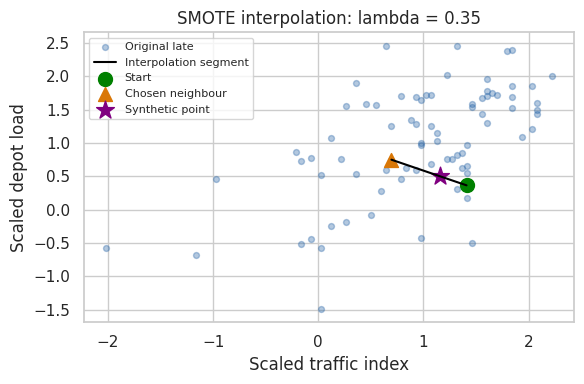

In [19]:
x_new = x_i + lam * (x_j - x_i)
display(pd.DataFrame([x_i, x_j, x_new],
                      index=['Start', 'Neighbour', 'Synthetic'],
                      columns=numeric_features).round(3))
a, b = numeric_features.index('traffic_index'), numeric_features.index('depot_load_pct')
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(minority[:, a], minority[:, b], s=18, color=BLUE, alpha=0.35, label='Original late')
ax.plot([x_i[a], x_j[a]], [x_i[b], x_j[b]], color='black', label='Interpolation segment')
ax.scatter(x_i[a], x_i[b], s=100, marker='o', color='green', label='Start')
ax.scatter(x_j[a], x_j[b], s=100, marker='^', color=ORANGE, label='Chosen neighbour')
ax.scatter(x_new[a], x_new[b], s=180, marker='*', color='purple', label='Synthetic point')
ax.set(title=f'SMOTE interpolation: lambda = {lam}',
       xlabel='Scaled traffic index', ylabel='Scaled depot load')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Your answer:** _Explain the interpolation, neighbour choice and projection here._


**Lecturer solution and teaching notes**

Lambda 0 returns the starting point; lambda 1 returns the neighbour; lambda 0.35 moves 35% of the way along the segment. Intermediate lambdas give a convex combination of two minority points. Ordinary SMOTE assigns the minority label to the synthetic point, so it uses minority neighbours. Interpolation can still cross an unsuitable region when classes overlap.

Distances were calculated using all five scaled features. Two points that look close in this projection may differ strongly in distance, weight or rain. This cell illustrates SMOTE's interpolation rule with a fixed neighbour and fraction; the library normally samples neighbour choices and fractions at random. Synthetic points are not guaranteed to describe feasible combinations in a real delivery system.


## Optional C: Which feature pair separates the classes? (about 8 minutes)
**Slides 39–40**

Plot `traffic_index` versus `depot_load_pct` coloured by delivery outcome. Compare it with `parcel_weight_kg` versus `rain_mm` using the same class colours. Which pair shows more useful class structure? Do the classes form perfectly separate groups?

**Hint:** `sns.scatterplot(..., hue='late', hue_order=[0, 1], palette={0: BLUE, 1: ORANGE})`. Each point is an original training observation. Avoid claiming predictive performance from a plot alone.


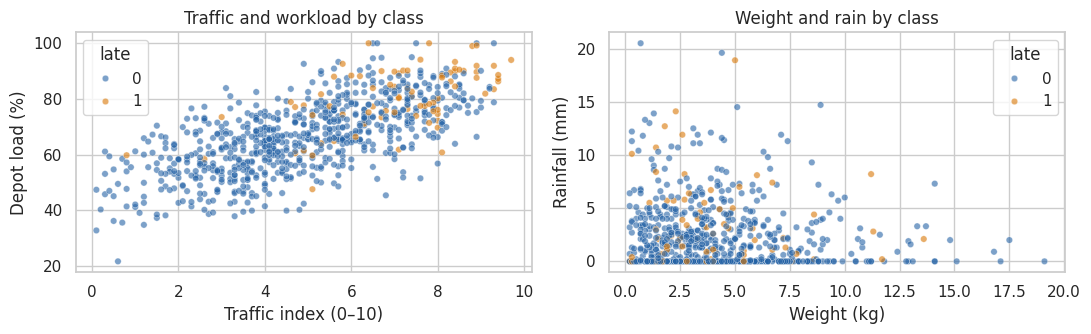

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.scatterplot(data=eda, x='traffic_index', y='depot_load_pct', hue='late',
                hue_order=[0, 1], palette={0: BLUE, 1: ORANGE}, alpha=0.6, s=22, ax=axes[0])
sns.scatterplot(data=eda, x='parcel_weight_kg', y='rain_mm', hue='late',
                hue_order=[0, 1], palette={0: BLUE, 1: ORANGE}, alpha=0.6, s=22, ax=axes[1])
axes[0].set(title='Traffic and workload by class', xlabel='Traffic index (0–10)', ylabel='Depot load (%)')
axes[1].set(title='Weight and rain by class', xlabel='Weight (kg)', ylabel='Rainfall (mm)')
plt.tight_layout()
plt.show()


**Your answer:** _Compare the class structure and overlap here._


**Lecturer solution and teaching notes**

There are two outcome classes. Late deliveries tend to occur in the higher-traffic/higher-workload region, but both classes overlap. Weight and rain provide weaker visual separation in this example. Weight is deliberately absent from the simulated risk formula; rain contributes a weaker noisy signal. A plot can suggest candidates to investigate, but feature selection and model comparison need training-based validation.


## Optional D: Tune SMOTE inside cross-validation (about 15 minutes)
**Extension of slides 2 and 19–20**

This exercise introduces cross-validation. Split the **original training data** into three folds, rotate the validation fold, and summarise validation scores. Inside each fold, an `imblearn` pipeline fits an imputer, a scaler, SMOTE and a classifier. The held-out fold keeps its original class proportions and receives no synthetic points.

Complete the SMOTE pipeline step. The supplied loop compares `k_neighbors` in `[3, 5]` and `sampling_strategy` in `[0.5, 1.0]`. For this binary dataset, the ratio means **minority / majority after resampling**. Rank by mean validation F1 and inspect mean precision and recall as well.

**Hint:** `SMOTE(random_state=SEED, k_neighbors=k, sampling_strategy=ratio)`. Use `X_train` with its original missing entries here, so preprocessing is learned separately inside each fold. Do not use the already prepared training matrix or tune on `X_test`.


In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for k in [3, 5]:
    for ratio in [0.5, 1.0]:
        cv_sampler = SMOTE(random_state=SEED, k_neighbors=k, sampling_strategy=ratio)
        pipeline = ImbPipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('smote', cv_sampler),
            ('classifier', LogisticRegression(max_iter=1000, random_state=SEED)),
        ])
        scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                                scoring=['precision', 'recall', 'f1', 'balanced_accuracy'],
                                n_jobs=1, error_score='raise')
        cv_rows.append({'k': k, 'minority/majority ratio': ratio,
                        'Precision mean': scores['test_precision'].mean(),
                        'Recall mean': scores['test_recall'].mean(),
                        'F1 mean': scores['test_f1'].mean(),
                        'F1 std': scores['test_f1'].std(),
                        'Balanced accuracy mean': scores['test_balanced_accuracy'].mean()})
cv_results = pd.DataFrame(cv_rows).sort_values('F1 mean', ascending=False)
display(cv_results.round(3))


,k,minority/majority ratio,Precision mean,Recall mean,F1 mean,F1 std,Balanced accuracy mean
2,5,0.5,0.380,0.662,0.479,0.049,0.768
0,3,0.5,0.363,0.638,0.461,0.056,0.754
1,3,1.0,0.288,0.774,0.419,0.018,0.781
3,5,1.0,0.277,0.787,0.409,0.004,0.779


**Your answer:** Which setting has the highest mean validation F1? Explain why balancing/scaling the entire training partition once before cross-validation would still leak information between folds. Why might another business objective lead you to a different setting?

_Write your answer here._


**Lecturer solution and teaching notes**

With the fixed data and package pair, **k=5 and ratio=0.5** has the highest mean validation F1 (**0.479**, standard deviation **0.049**). Its mean precision is **0.380** and mean recall **0.662**. Its rank comes from training folds only. The pipeline learns medians, scaling statistics and synthetic points separately inside each fold's training subset. Preprocessing/resampling before cross-validation would let held-out fold information influence fitting, even though the final test set was kept separate.

A minority/majority ratio of 0.5 gives more minority examples without full balance. It can trade recall for precision differently from ratio 1.0. If missing delays is more costly, recall or a cost-sensitive measure could be the selection objective. With only three folds, small score differences and their standard deviations should be interpreted cautiously. This extension does not re-evaluate new choices on the core exercise's already inspected test set. A separate final evaluation would be needed for a model-selection study.


## Reference documentation

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html): notebook upload and runtime behaviour.
- [imbalanced-learn installation](https://imbalanced-learn.org/stable/install.html): install `imbalanced-learn`, import `imblearn`.
- [Resampling pitfalls](https://imbalanced-learn.org/stable/common_pitfalls.html): preserve evaluation data and avoid leakage.
- [SMOTE API](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html): neighbour count and sampling strategy.
- [StratifiedKFold API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html): optional fold construction.

Lecture source: the attached 41-slide Week 3 Lecture 1 deck. The parcel-delivery simulation, exercises and interpretations in this notebook are new teaching material.
